**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

---

Prepared by: Ecem Tas

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

Missing values:
bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
dtype: int64
Missing values after cleaning:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64
Remainings: 342


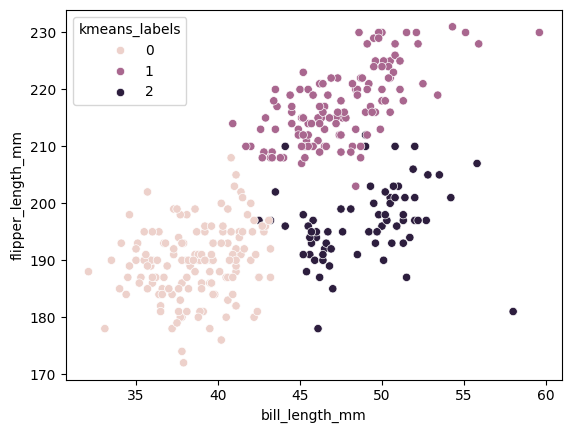

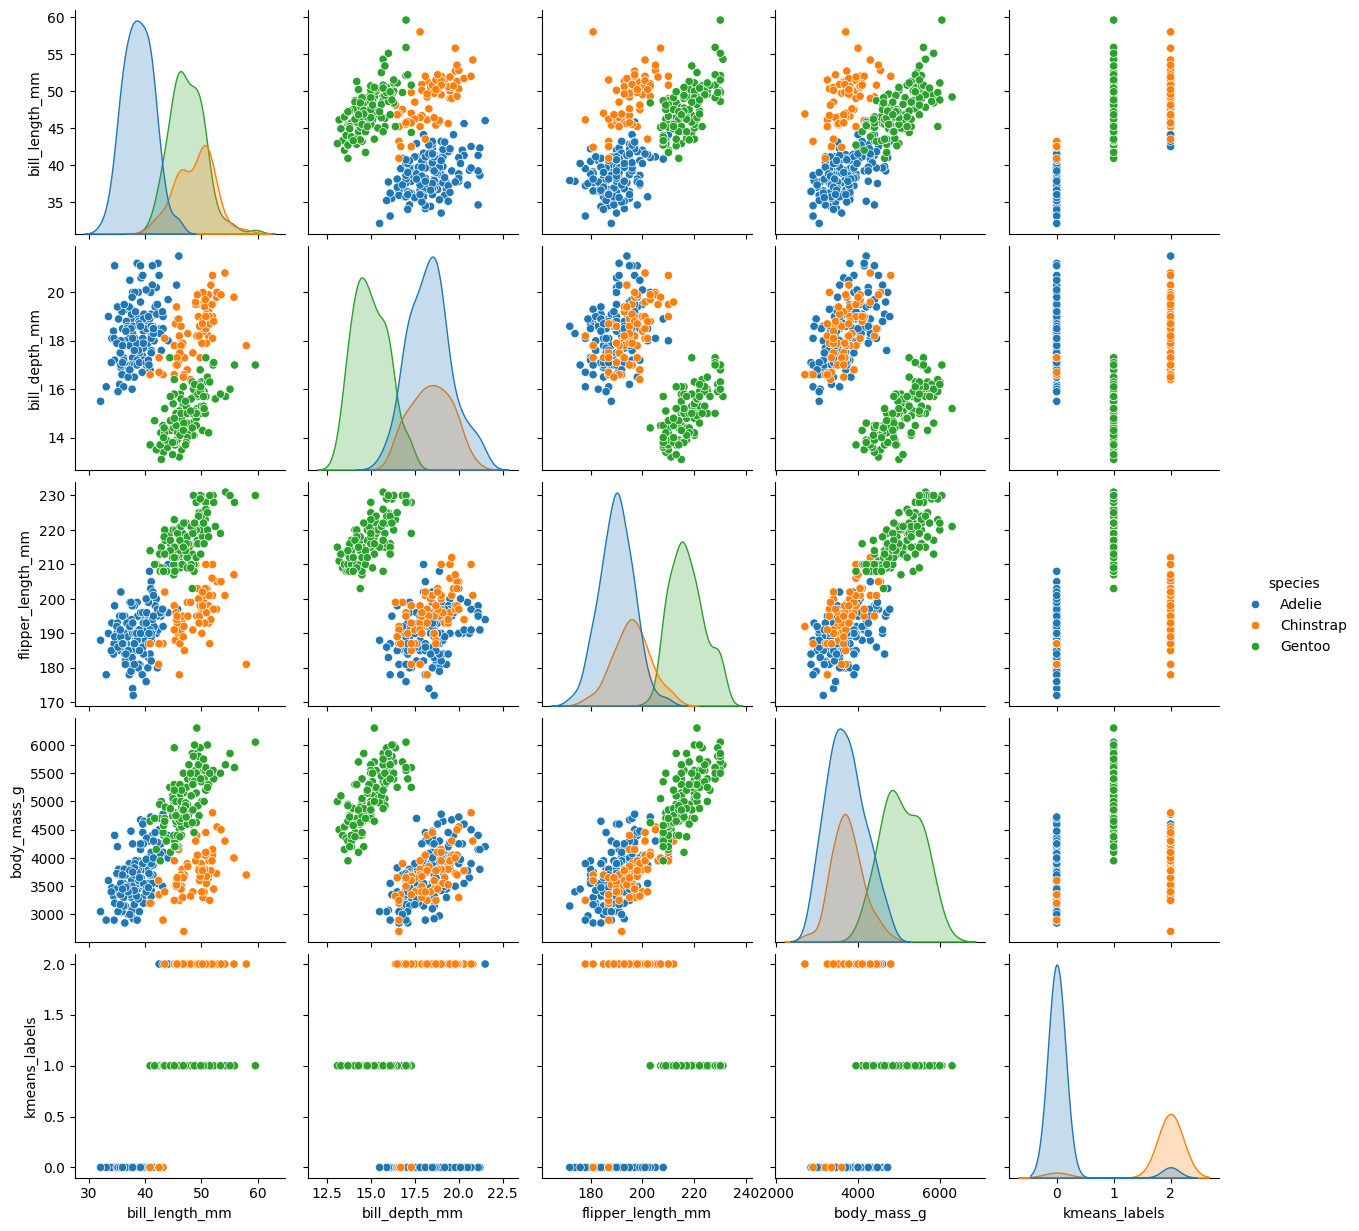

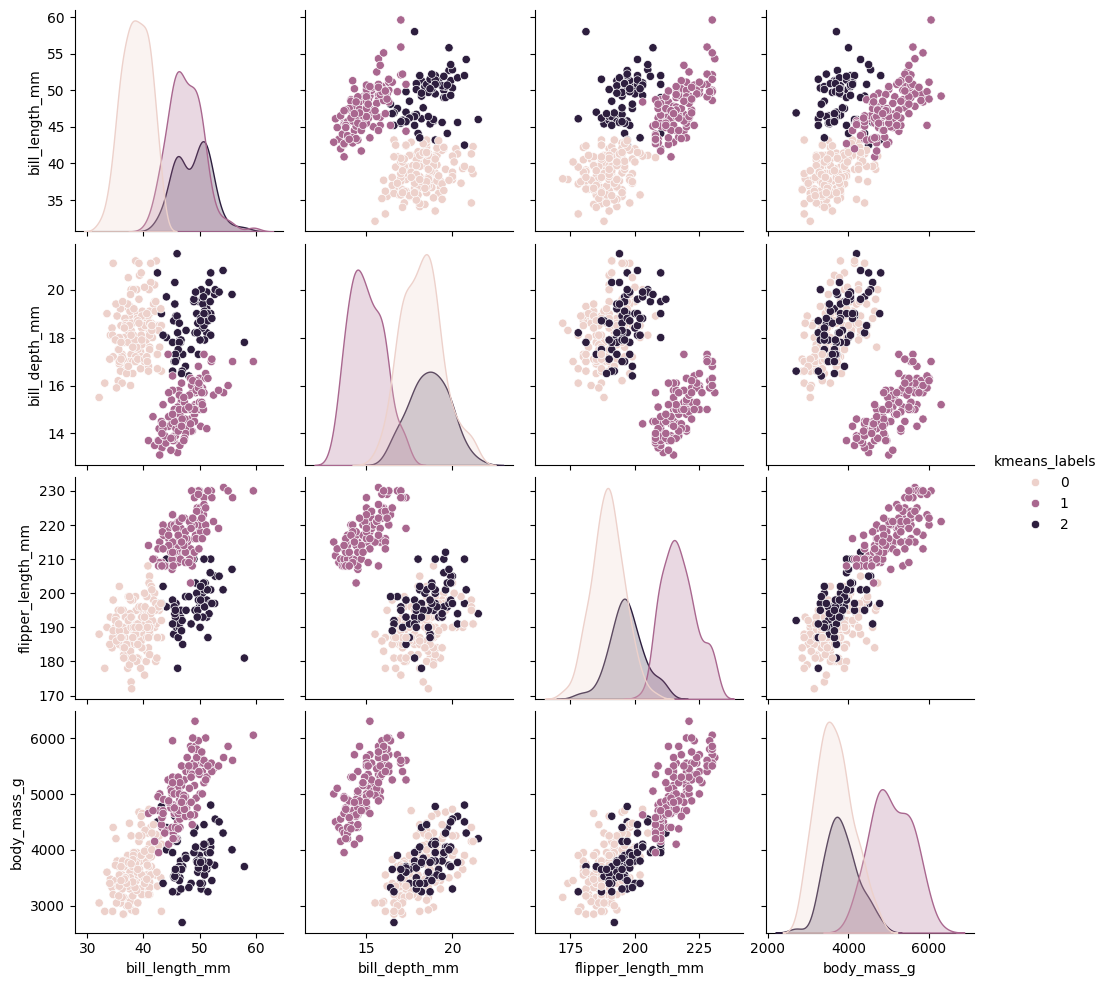

Confusion matrix: [[144   5   0]
 [  0   0 123]
 [  7  63   0]]
Adjusted Rand score: 0.9076181508927866
Adjusted Rand score (raw): 0.31811783348725337


In [63]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# a) Check missing values per column

print("Missing values:")
print(penguins[num_cols].isna().sum())

penguins_clean = penguins[num_cols + ['species']].dropna().copy()

print("Missing values after cleaning:")
print(penguins_clean[num_cols].isna().sum())

print("Remainings:", len(penguins_clean))

# b) Normalize the numeric columns with StandardScaler

scaler = StandardScaler()
penguins_scaled_df = pd.DataFrame(scaler.fit_transform(penguins_clean[num_cols]), columns=num_cols,
index=penguins_clean.index)

# c) KMeans with n_clusters=3 on the normalized data

kmeans_labels = KMeans(n_clusters=3).fit_predict(penguins_scaled_df)

# d) Make plots

penguins_clean['kmeans_labels'] = kmeans_labels
sns.scatterplot(data=penguins_clean, x='bill_length_mm', y='flipper_length_mm', hue='kmeans_labels')
plt.show()
sns.pairplot(data=penguins_clean, hue='species')
plt.show()
sns.pairplot(data=penguins_clean, hue='kmeans_labels')
plt.show()

# e) Confusion matrix and adjusted Rand score vs real 'species'

encoder= LabelEncoder()
species_encoded = encoder.fit_transform(penguins_clean['species'])
cm = confusion_matrix(kmeans_labels, species_encoded)
print("Confusion matrix:",cm)
ari_scaled = adjusted_rand_score(kmeans_labels, species_encoded)
print("Adjusted Rand score:", ari_scaled)

# f) Interpretation

raw_kmeans_labels = KMeans(n_clusters=3).fit_predict(penguins_clean[num_cols])
ari_raw = adjusted_rand_score(raw_kmeans_labels, species_encoded)
print("Adjusted Rand score (raw):", ari_raw)

---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

Check for missing values: False
5.656854249492381
5.656854249492381


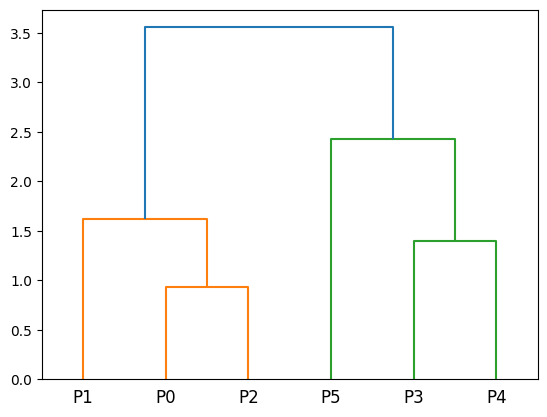

Agglomerative labels: [1 1 1 0 0 0]
K-Means labels: [0 0 0 1 1 0]


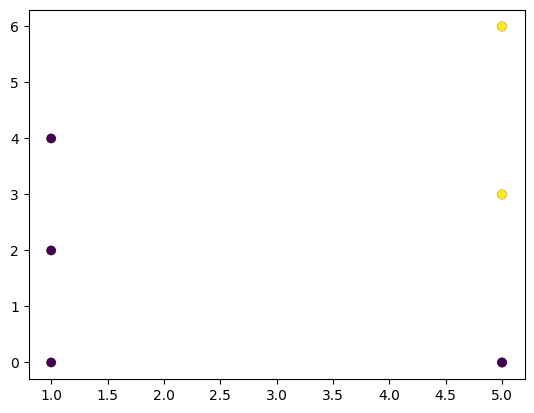

False
None
None


In [64]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) Check for missing values with np.isnan(X).any()

print("Check for missing values:",np.isnan(X).any())

# b) Normalize X with StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# c) Plain-Python euclidean_distance function using a for loop (no
# numpy/sklearn)
def euclidean_distance(p1, p2):
  squared_sum = 0
  for i in range(len(p1)):
    squared_sum += (p1[i] - p2[i]) ** 2
  return squared_sum ** 0.5

# test it
print(euclidean_distance(X[0], X[3]))
print(np.linalg.norm(X[0] - X[3]))

# d) Agglomerative clustering on X_scaled + dendrogram

agglo = AgglomerativeClustering(n_clusters=2, linkage='ward')

agglo_labels = agglo.fit_predict(X_scaled)
Z=linkage(X_scaled, method='ward')
dendrogram(Z, labels=[f'P{i}'for i in range (len(X))])
plt.show()

# e) k-means clustering with n_clusters=2 on X_scaled
kmeans_labels = KMeans(n_clusters=2).fit_predict(X_scaled)

# f) Compare both label arrays and make a side-by-side scatterplot

print('Agglomerative labels:', agglo_labels)
print('K-Means labels:', kmeans_labels)
plt.scatter(X[:, 0], X[:, 1], c=agglo_labels)
plt.scatter(X[:, 0], X[:, 1], c=kmeans_labels)
plt.show()
print(np.array_equal(agglo_labels, kmeans_labels))

# g) Cluster_sizes function using a dictionary
def cluster_sizes(labels):
  cluster_sizes = {}
  for label in labels:
    if label not in cluster_sizes:
      cluster_sizes[label] = 0
    else:
      cluster_sizes[label] += 1
    pass

print(cluster_sizes(agglo_labels))
print(cluster_sizes(kmeans_labels))

---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

Missing values:
carat    0
depth    0
table    0
price    0
dtype: int64
Missing values after cleaning:
carat    0
depth    0
table    0
price    0
dtype: int64
Remainings: 1000


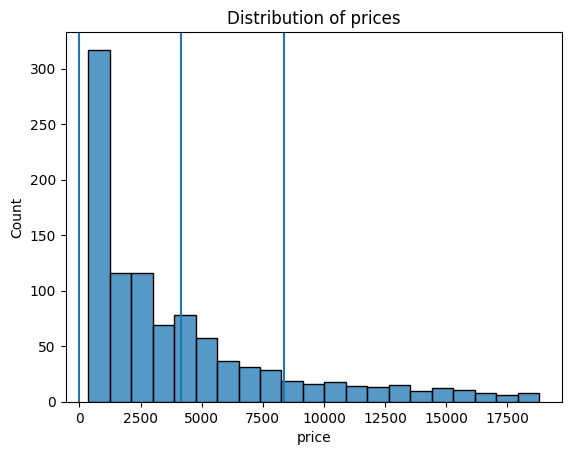

Means: [-0.  0. -0. -0.]
Stds: [1. 1. 1. 1.]


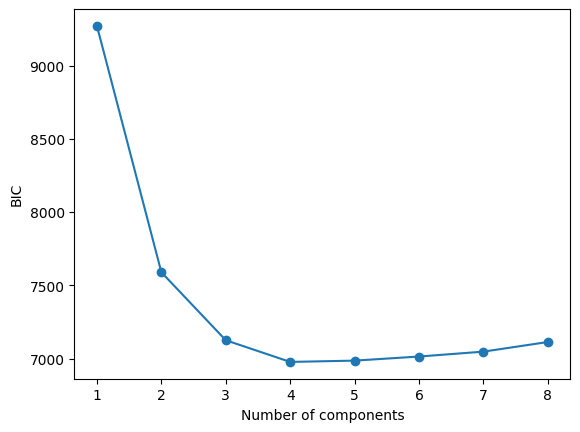

Best number of components: 4


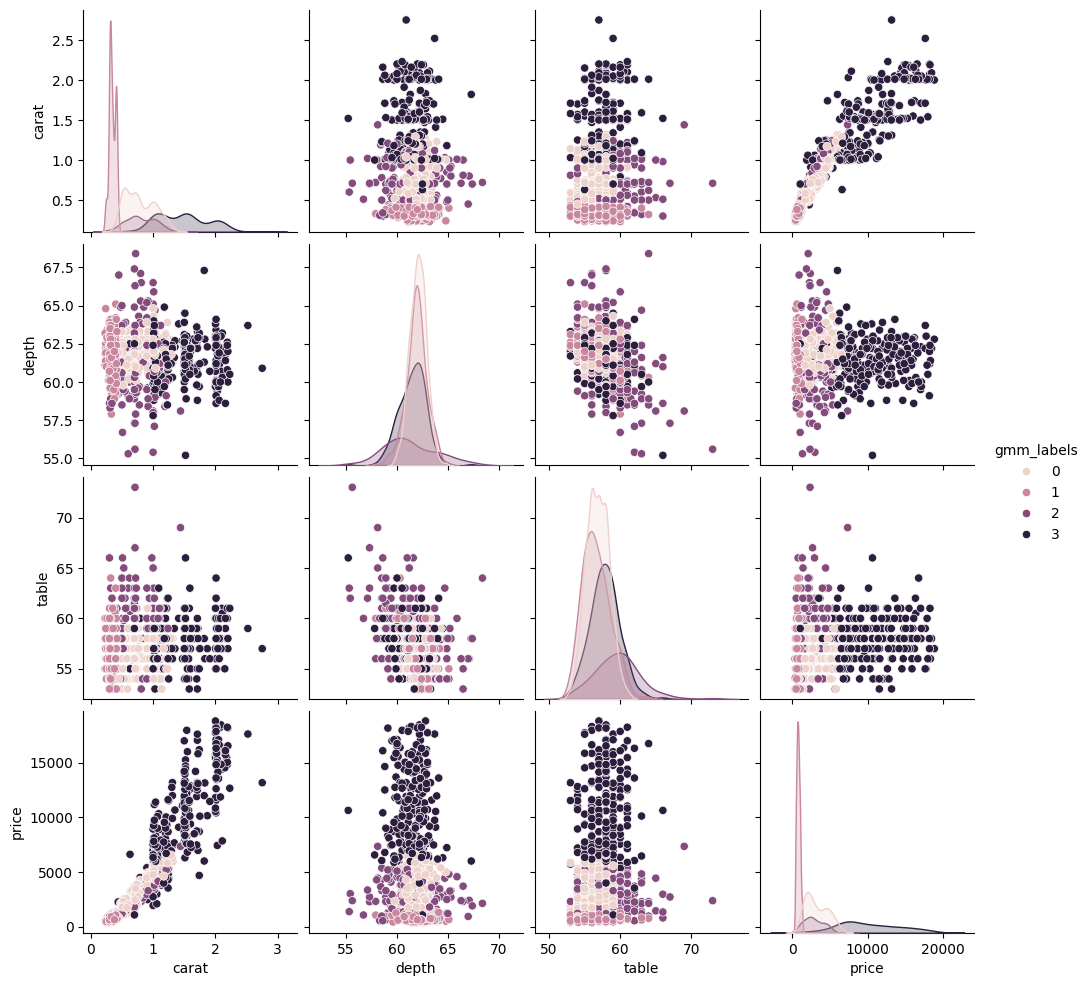

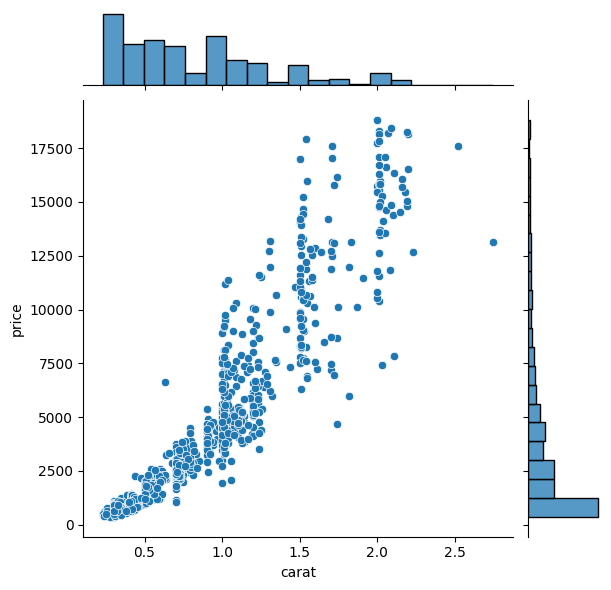

Best number of components (raw): 5


In [78]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) Select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean

num_cols = ['carat','depth','table','price']
diamonds_num = diamonds[num_cols].copy()

print('Missing values:')
print(diamonds_num.isna().sum())

diamonds_num= diamonds_num.dropna()

print('Missing values after cleaning:')
print(diamonds_num.isna().sum())
print('Remainings:',len(diamonds_num))

# b) Histogram of 'price' with mean and mean +/- std lines

mean_price = diamonds_num['price'].mean()
std_price = diamonds_num['price'].std()

plt.figure
sns.histplot(data = diamonds_num, x='price')

plt.axvline(mean_price, label='Mean')
plt.axvline(mean_price + std_price, label='Mean - SD')
plt.axvline(mean_price - std_price, label='Mean + SD')
plt.title('Distribution of prices')
plt.show()

# c) Normalize the 4 numeric columns with StandardScaler

scaler= StandardScaler()

diamonds_scaled = scaler.fit_transform(diamonds_num[num_cols])

print('Means:',np.round(diamonds_scaled.mean(axis=0),3))
print('Stds:',np.round(diamonds_scaled.std(axis=0),3))

# d) Fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components
bic = []
n_components_range = range(1, 9)

for n in n_components_range:
  gmm = mixture.GaussianMixture(n_components=n)
  gmm.fit(diamonds_scaled)
  bic.append(gmm.bic(diamonds_scaled))

plt.plot(n_components_range, bic, marker='o')
plt.xlabel('Number of components')
plt.ylabel('BIC')
plt.show()


# e) Find the number of components that minimizes BIC and fit the final GMM

best_n = list(n_components_range)[np.argmin(bic)]

gmm = mixture.GaussianMixture(n_components=best_n)
gmm.fit(diamonds_scaled)
gmm_labels = gmm.fit_predict(diamonds_scaled)

print('Best number of components:',best_n)

# f) Add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)

diamonds_num['gmm_labels'] = gmm_labels

sns.pairplot(data=diamonds_num, hue='gmm_labels')
plt.show()

sns.jointplot(data=diamonds_num, x='carat', y='price')
plt.show()

# g) Interpretation

bic_raw = []

for n in n_components_range:
  gmm_raw = mixture.GaussianMixture(n_components=n)
  gmm_raw.fit(diamonds_num[num_cols])
  bic_raw.append(gmm_raw.bic(diamonds_num[num_cols]))

n_raw = list(n_components_range)[np.argmin(bic_raw)]
print('Best number of components (raw):', n_raw)
